# BIC order-selection experiments

This notebook contains the BIC-specific Monte Carlo experiment moved from `ar_order_minimum_width.ipynb`. It evaluates Gaussian BIC after conditional least-squares AR fitting on stationary processes with bounded $\operatorname{Uniform}[-1,1]$ innovations.


In [ ]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt                                                                     ### PLOTTING
import numpy as np
import pandas as pd

AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            root / "Code" / "Code_AR_processes",
            root,
        )
        if (candidate / "functions.py").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError(
        "Could not locate Code/Code_AR_processes from the current directory."
    )
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Code.Code_AR_processes import functions as ar_functions

ar_functions = importlib.reload(ar_functions)

from Code.Code_AR_processes.functions import (
    aic_bic_ar_order,
    jones_ar_coefficients,
    simulate_uniform_ar,
)

plt.style.use(style="seaborn-v0_8-whitegrid")                                                       ### PLOTTING
np.set_printoptions(precision=4, suppress=True)                                                     ### REPORTING


## BIC experiment for AR orders 1 through 10

For each true order, this experiment generates 100 independently parameterized stationary AR processes with uniform innovations, sample size 2,000, and burn-in 1,000. BIC searches candidate orders 0 through 15 so that the experiment at true order 10 is not artificially helped by a search boundary at 10.

BIC accuracy by true AR order
            correct_count  accuracy
true_order                         
1                      95      0.95
2                      92      0.92
3                      91      0.91
4                      96      0.96
5                      83      0.83
6                      86      0.86
7                      87      0.87
8                      92      0.92
9                      82      0.82
10                     87      0.87

Overall: 891/1000

Selected-order distributions
selected_order  0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15
true_order                                                                    
1                4  95   1   0   0   0   0   0   0   0   0   0   0   0   0   0
2                0   8  92   0   0   0   0   0   0   0   0   0   0   0   0   0
3                0   2   5  91   0   1   1   0   0   0   0   0   0   0   0   0
4                0   0   1   3  96   0   0   0   0   0   0   0   0   0   0   0
5              

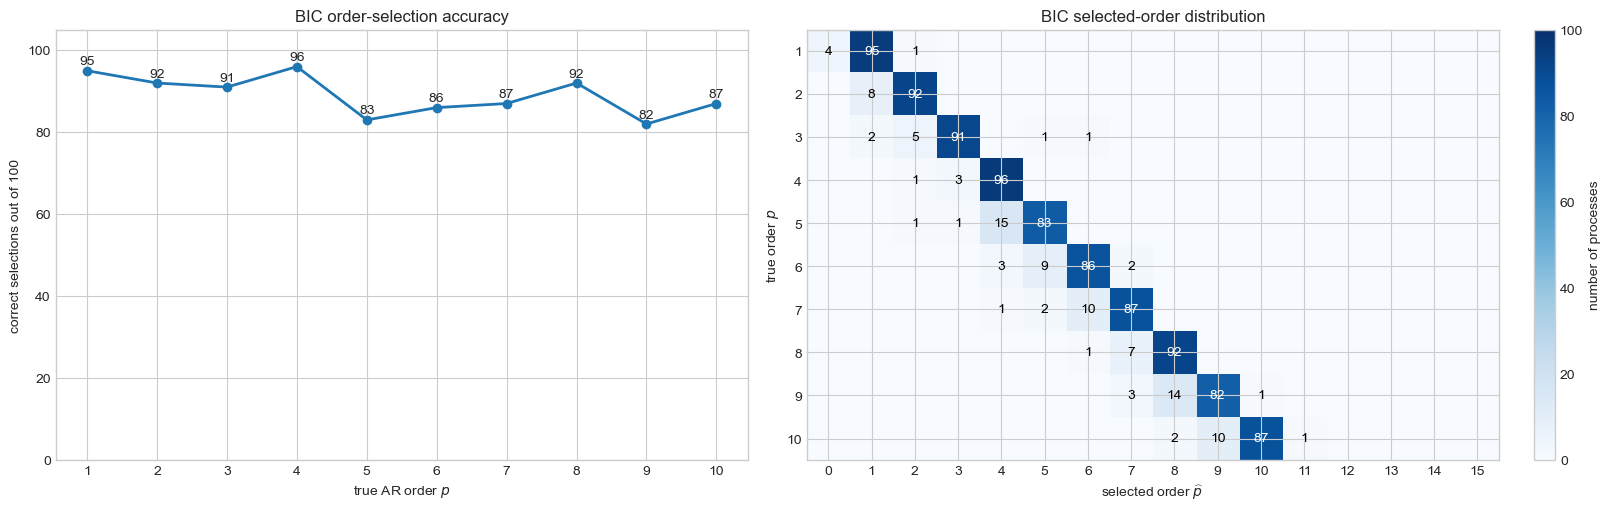

In [26]:
bic_all_order_rows = []
bic_all_order_replications = 100
bic_all_order_sample_size = 2_000
bic_all_order_burnin = 1_000
bic_all_order_maximum_candidate = 15

for true_order in range(1, 11):
    experiment_seed = 20260820 + true_order
    for replication in range(bic_all_order_replications):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=bic_all_order_sample_size,
            burnin=bic_all_order_burnin,
            half_width=1.0,
            rng=process_generator,
        )
        _, selected_order, _ = aic_bic_ar_order(
            series_replication,
            maximum_order=bic_all_order_maximum_candidate,
        )
        bic_all_order_rows.append({
            "true_order": true_order,
            "replication": replication,
            "selected_order": selected_order,
            "correct": selected_order == true_order,
            "absolute_final_coefficient": abs(phi_replication[-1]),
        })

bic_all_order_results = pd.DataFrame(bic_all_order_rows)
bic_all_order_summary = (
    bic_all_order_results
    .groupby("true_order")["correct"]
    .agg(correct_count="sum", accuracy="mean")
)
bic_all_order_distribution = (
    bic_all_order_results
    .groupby(["true_order", "selected_order"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=np.arange(16), fill_value=0)
)
print("BIC accuracy by true AR order")                                                              ### REPORTING
print(bic_all_order_summary.to_string())                                                            ### REPORTING
print(                                                                                              ### REPORTING
    f"\nOverall: {bic_all_order_summary['correct_count'].sum()}/"                                   ### REPORTING
    f"{10 * bic_all_order_replications}"                                                            ### REPORTING
)                                                                                                   ### REPORTING
print("\nSelected-order distributions")                                                             ### REPORTING
print(bic_all_order_distribution.to_string())                                                       ### REPORTING

fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)                            ### PLOTTING
axes[0].plot(                                                                                       ### PLOTTING
    bic_all_order_summary.index,                                                                    ### PLOTTING
    bic_all_order_summary["correct_count"],                                                         ### PLOTTING
    marker="o",                                                                                     ### PLOTTING
    linewidth=2,                                                                                    ### PLOTTING
    color="tab:blue",                                                                               ### PLOTTING
)                                                                                                   ### PLOTTING
for order, count in bic_all_order_summary["correct_count"].items():                                 ### PLOTTING
    axes[0].text(order, count + 1.5, str(count), ha="center")                                       ### PLOTTING
axes[0].set(                                                                                        ### PLOTTING
    title="BIC order-selection accuracy",                                                           ### PLOTTING
    xlabel=r"true AR order $p$",                                                                    ### PLOTTING
    ylabel="correct selections out of 100",                                                         ### PLOTTING
    xticks=np.arange(1, 11),                                                                        ### PLOTTING
    ylim=(0, 105),                                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING

confusion_values = bic_all_order_distribution.to_numpy()                                            ### PLOTTING
image = axes[1].imshow(                                                                             ### PLOTTING
    confusion_values,                                                                               ### PLOTTING
    cmap="Blues",                                                                                   ### PLOTTING
    vmin=0,                                                                                         ### PLOTTING
    vmax=100,                                                                                       ### PLOTTING
    aspect="auto",                                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING
for row in range(confusion_values.shape[0]):                                                        ### PLOTTING
    for column in range(confusion_values.shape[1]):                                                 ### PLOTTING
        if confusion_values[row, column] > 0:                                                       ### PLOTTING
            axes[1].text(                                                                           ### PLOTTING
                column, row, str(confusion_values[row, column]),                                    ### PLOTTING
                ha="center", va="center",                                                           ### PLOTTING
                color=(                                                                             ### PLOTTING
                    "white" if confusion_values[row, column] > 50                                   ### PLOTTING
                    else "black"                                                                    ### PLOTTING
                ),                                                                                  ### PLOTTING
            )                                                                                       ### PLOTTING
axes[1].set(                                                                                        ### PLOTTING
    title="BIC selected-order distribution",                                                        ### PLOTTING
    xlabel=r"selected order $\widehat p$",                                                          ### PLOTTING
    ylabel=r"true order $p$",                                                                       ### PLOTTING
    xticks=np.arange(16),                                                                           ### PLOTTING
    yticks=np.arange(10),                                                                           ### PLOTTING
    yticklabels=np.arange(1, 11),                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING
fig.colorbar(image, ax=axes[1], label="number of processes")                                        ### PLOTTING
plt.show()                                                                                          ### PLOTTING